# Defence analysis

Here I run backdoor defences on the models I already trained, without retraining anything. Most of it
uses the 1% models; Neural Cleanse and Fine-Pruning are also run on the SIG+WaNet variants at 0.5% and
5%. Figures go to `results/figures/` and tables to `results/`.

1. **STRIP** (Gao et al., 2019): mix each input with 100 clean images and look at the prediction
   entropy. Triggered inputs that keep predicting the target class have low entropy. I report the AUROC
   and the false acceptance rate (FAR) at a 1% false rejection rate (FRR).
2. **Grad-CAM** (Selvaraju et al., 2017): where does the model look? SentiNet and Februus assume the
   trigger is a small patch that Grad-CAM can find and remove. I check that for my whole-image triggers,
   with heatmaps and with a simple Februus-style test: cover the hot region and see if the backdoor
   still works.
3. **Data-level detection** on the poisoned training set: Spectral Signatures (Tran et al., 2018) and
   Activation Clustering (Chen et al., 2019). These fit my threat model, where the attacker only
   poisons data.
4. **Frequency domain** (Zeng et al., 2021): how concentrated each trigger is in the DCT spectrum, and
   how well a simple DCT-based detector separates clean from poisoned images, for triggers it was
   trained on and for triggers it has never seen.
5. **Neural Cleanse** (Wang et al., 2019): reverse-engineer the smallest trigger for every class and
   look for a class that needs an unusually small one.
6. **Fine-Pruning** (Liu et al., 2018): prune channels that clean images hardly use, then fine-tune.
   Section 6b checks how much both results depend on the defence settings.

Sections 5 and 6 also include a BadNets patch model as a sanity check. Those defences were designed
for that kind of trigger, so if they catch it, missing my triggers isn't a bug in my code.

Every trigger is rebuilt right after `set_seed(cfg.seed)`, like in `train.py`, so each model is tested
with the trigger it was trained on.

In [1]:
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import numpy as np
import pandas as pd
import torch, torchvision
import torchvision.transforms as T
import matplotlib.pyplot as plt

from config import cfg
from utils import set_seed, load_checkpoint
from models.resnet import get_model
from datasets.poison_dataset import build_attack
from defenses.strip import strip_entropy, strip_metrics
from defenses.gradcam import GradCAM, cam_spread
from defenses.spectral import extract_features, spectral_signatures, activation_clustering
from defenses.frequency import dct2, energy_concentration, train_dct_detector
from defenses.neural_cleanse import neural_cleanse
from defenses.fine_pruning import fine_prune
from datasets.poison_dataset import PoisonedDataset

FIG_DIR = os.path.join(cfg.results_dir, "figures")
os.makedirs(FIG_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 11, "axes.titlesize": 11, "axes.labelsize": 11,
                     "legend.fontsize": 9.5, "xtick.labelsize": 10, "ytick.labelsize": 10})
DEVICE = cfg.device
NORMALIZE = T.Normalize(mean=[0.4914, 0.4822, 0.4465], std=[0.2470, 0.2435, 0.2616])
to_tensor = T.ToTensor()
test_base = torchvision.datasets.CIFAR10(root=cfg.data_root, train=False, download=True)
CLASSES = test_base.classes
RATE = 0.01

ADAPTIVE_V1 = dict(adaptive_texture_mask=False,
                   adaptive_hybrid_alpha_min=0.45, adaptive_hybrid_alpha_max=0.80,
                   adaptive_hybrid_beta_min=6.0, adaptive_hybrid_beta_max=22.0,
                   adaptive_hybrid_cover_alpha=0.20)
# display name -> (attack name, config changes, checkpoint folder)
MODELS = {
    "Blend":                     ("blend", {}, cfg.checkpoint_dir),
    "SIG (dirty-label)":         ("sig", {"sig_clean_label": False}, cfg.checkpoint_dir),
    "WaNet":                     ("wanet", {}, cfg.checkpoint_dir),
    "Blend+SIG+WaNet":           ("blend_sig_wanet", {}, cfg.checkpoint_dir),
    "SIG+WaNet (Fixed)":         ("sig_wanet", {}, cfg.checkpoint_dir),
    "SIG+WaNet (Fixed, matched)": ("sig_wanet_matched", {}, cfg.checkpoint_dir),
    "Adaptive v1":               ("adaptive_hybrid", ADAPTIVE_V1, os.path.join(cfg.checkpoint_dir, "adaptive_hybrid_v1_backup")),
    "Adaptive v2":               ("adaptive_hybrid", {}, cfg.checkpoint_dir),
}

EXTRA = {"Clean model": ("clean", {}, cfg.checkpoint_dir),
         "BadNets (control)": ("badnets", {}, cfg.checkpoint_dir)}

def load(name, rate=RATE):
    """Load a trained model together with its trigger (built the same way as in evaluate.py)."""
    attack_name, overrides, folder = {**MODELS, **EXTRA}[name]
    rate = 0.0 if attack_name == "clean" else rate
    saved = {k: getattr(cfg, k) for k in overrides}
    saved.update(attack_name=cfg.attack_name, poison_rate=cfg.poison_rate)
    try:
        for k, v in overrides.items():
            setattr(cfg, k, v)
        cfg.attack_name, cfg.poison_rate = attack_name, rate
        set_seed(cfg.seed)
        attack = build_attack(cfg)
        path = os.path.join(folder, f"{cfg.tag()}_final.pt")
    finally:
        for k, v in saved.items():
            setattr(cfg, k, v)
    model = get_model(cfg.model_name, cfg.num_classes).to(DEVICE)
    load_checkpoint(model, None, path, DEVICE)
    return attack, model.eval()

@torch.no_grad()
def predict(model, images):
    return torch.cat([model(NORMALIZE(images[i:i + 500]).to(DEVICE)).argmax(1).cpu() for i in range(0, len(images), 500)])

## 1. STRIP

**Data (all from the CIFAR-10 test set, fixed seed):** 1,000 clean inputs, 1,000 triggered inputs made
from other non-airplane test images, and a separate pool of 2,000 clean images that are only used for
mixing. Each input is mixed 50/50 with 100 random images from the pool.

The main numbers only use the triggered inputs that actually make the model say airplane - a trigger
that doesn't work doesn't need detecting. The AUROC over all triggered inputs is given too.

In [2]:
rng = np.random.RandomState(cfg.seed)
perm = rng.permutation(len(test_base))
labels = np.array(test_base.targets)
clean_idx = perm[:1000]
nontarget = [i for i in perm[1000:] if labels[i] != cfg.target_label]
trig_idx = nontarget[:1000]
pool_idx = perm[3000:5000]                       # no overlap with either set of inputs
assert not set(pool_idx) & set(clean_idx) and not set(pool_idx) & set(trig_idx)

clean_imgs = torch.stack([to_tensor(test_base[i][0]) for i in clean_idx])
overlay_pool = torch.stack([to_tensor(test_base[i][0]) for i in pool_idx])
base_trig = [to_tensor(test_base[i][0]) for i in trig_idx]

rows, entropies = [], {}
for name in MODELS:
    attack, model = load(name)
    poisoned = torch.stack([attack.poison(x) for x in base_trig])
    success = (predict(model, poisoned) == cfg.target_label).numpy()
    h_clean = strip_entropy(model, clean_imgs, overlay_pool, NORMALIZE, device=DEVICE)
    h_pois = strip_entropy(model, poisoned, overlay_pool, NORMALIZE, device=DEVICE)
    m = strip_metrics(h_clean, h_pois[success])
    m_all = strip_metrics(h_clean, h_pois)
    entropies[name] = (h_clean, h_pois[success])
    rows.append({"attack": name, "triggered_success_rate": success.mean(), "auroc": m["auroc"],
                 "far_at_1pct_frr": m["far_at_1pct_frr"], "auroc_all_triggered": m_all["auroc"],
                 "clean_entropy_mean": m["clean_entropy_mean"], "poisoned_entropy_mean": m["poisoned_entropy_mean"]})
    print(f"{name:28s} AUROC {m['auroc']:.3f}  FAR@1%FRR {m['far_at_1pct_frr']:.1%}  "
          f"(success {success.mean():.1%}, AUROC all triggered {m_all['auroc']:.3f})", flush=True)

strip_df = pd.DataFrame(rows)
strip_df.to_csv(os.path.join(cfg.results_dir, "strip_results.csv"), index=False)
strip_df.round(3)

Blend                        AUROC 0.468  FAR@1%FRR 99.9%  (success 95.9%, AUROC all triggered 0.461)


SIG (dirty-label)            AUROC 0.680  FAR@1%FRR 92.9%  (success 98.6%, AUROC all triggered 0.680)


WaNet                        AUROC 0.591  FAR@1%FRR 100.0%  (success 54.4%, AUROC all triggered 0.553)


Blend+SIG+WaNet              AUROC 0.645  FAR@1%FRR 98.7%  (success 89.2%, AUROC all triggered 0.619)


SIG+WaNet (Fixed)            AUROC 0.675  FAR@1%FRR 98.2%  (success 95.3%, AUROC all triggered 0.661)


SIG+WaNet (Fixed, matched)   AUROC 0.691  FAR@1%FRR 98.2%  (success 96.1%, AUROC all triggered 0.679)


Adaptive v1                  AUROC 0.841  FAR@1%FRR 84.2%  (success 98.9%, AUROC all triggered 0.836)


Adaptive v2                  AUROC 0.728  FAR@1%FRR 88.9%  (success 97.1%, AUROC all triggered 0.719)


,attack,triggered_success_rate,auroc,far_at_1pct_frr,auroc_all_triggered,clean_entropy_mean,poisoned_entropy_mean
0,Blend,0.959,0.468,0.999,0.461,0.941,0.971
1,SIG (dirty-label),0.986,0.680,0.929,0.680,0.939,0.744
2,WaNet,0.544,0.591,1.000,0.553,0.937,0.888
3,Blend+SIG+WaNet,0.892,0.645,0.987,0.619,0.932,0.810
4,SIG+WaNet (Fixed),0.953,0.675,0.982,0.661,0.897,0.744
5,"SIG+WaNet (Fixed, matched)",0.961,0.691,0.982,0.679,0.888,0.714
6,Adaptive v1,0.989,0.841,0.842,0.836,0.905,0.528
7,Adaptive v2,0.971,0.728,0.889,0.719,0.929,0.689


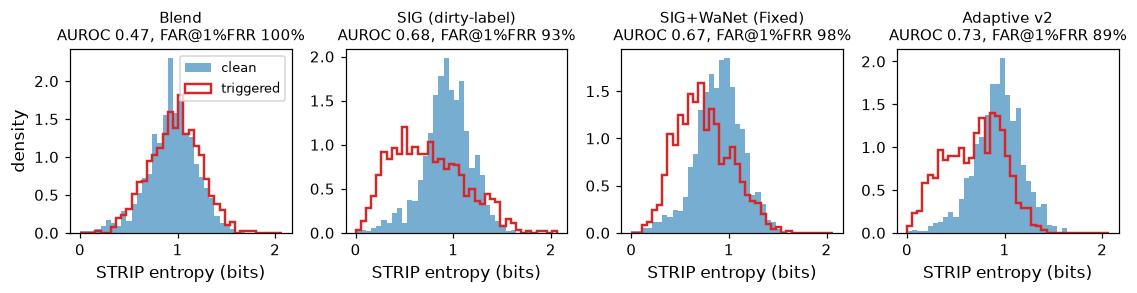

In [3]:
show = ["Blend", "SIG (dirty-label)", "SIG+WaNet (Fixed)", "Adaptive v2"]
fig, axes = plt.subplots(1, len(show), figsize=(2.6 * len(show), 2.8), sharey=False)
bins = np.linspace(0, max(max(h.max() for h in pair) for pair in entropies.values()), 40)
for ax, name in zip(axes, show):
    h_clean, h_pois = entropies[name]
    r = strip_df.set_index("attack").loc[name]
    ax.hist(h_clean, bins=bins, alpha=0.6, density=True, label="clean", color="tab:blue")
    # outline only, so the two histograms can be told apart without colour
    ax.hist(h_pois, bins=bins, density=True, label="triggered", color="tab:red", histtype="step", lw=1.6)
    ax.set_title(f"{name}\nAUROC {r.auroc:.2f}, FAR@1%FRR {r.far_at_1pct_frr:.0%}", fontsize=9.5)
    ax.set_xlabel("STRIP entropy (bits)")
axes[0].set_ylabel("density"); axes[0].legend(fontsize=8.5)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/strip_entropy_hist.png", bbox_inches="tight"); plt.show()

## 2. Grad-CAM

**Heatmaps.** For four test images: the clean image explained by the clean model, and the same image
with the Fixed and the Adaptive v2 trigger explained by the matching backdoored model (for the class
the model predicts).

In [4]:
clean_model = get_model(cfg.model_name, cfg.num_classes).to(DEVICE)
load_checkpoint(clean_model, None, os.path.join(cfg.checkpoint_dir, "cifar10_resnet18_clean_pr0.0_final.pt"), DEVICE)
fixed_attack, fixed_model = load("SIG+WaNet (Fixed)")
v2_attack, v2_model = load("Adaptive v2")
cams = {"clean": GradCAM(clean_model), "fixed": GradCAM(fixed_model), "v2": GradCAM(v2_model)}

def explain(cam, img):
    heat, c = cam(NORMALIZE(img)[None].to(DEVICE))
    return heat, c

SHOW_IDX = [3, 6, 12, 25]
cols = ["Clean image", "Grad-CAM (clean model)", "Fixed SIG+WaNet", "Grad-CAM (Fixed model)", "Adaptive v2", "Grad-CAM (v2 model)"]
fig, axes = plt.subplots(len(SHOW_IDX), 6, figsize=(9, 1.6 * len(SHOW_IDX)))
for r, i in enumerate(SHOW_IDX):
    img = to_tensor(test_base[i][0])
    for c0, (key, x) in enumerate([("clean", img), ("fixed", fixed_attack.poison(img)), ("v2", v2_attack.poison(img))]):
        heat, pred = explain(cams[key], x)
        rgb = x.permute(1, 2, 0).numpy()
        axes[r, 2 * c0].imshow(rgb, interpolation="nearest")
        axes[r, 2 * c0 + 1].imshow(rgb, interpolation="nearest")
        axes[r, 2 * c0 + 1].imshow(heat, cmap="jet", alpha=0.5, vmin=0, vmax=1)
        axes[r, 2 * c0 + 1].set_xlabel(f"pred: {CLASSES[pred]}", fontsize=8.5)
    axes[r, 0].set_ylabel(CLASSES[test_base[i][1]], fontsize=9.5)
for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])
for c, t in enumerate(cols):
    axes[0, c].set_title(t, fontsize=9.5)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/gradcam_comparison.png", bbox_inches="tight"); plt.show()

C:\Users\ABC\AppData\Local\Temp\ipykernel_13048\3615992093.py:28: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.savefig(f"{FIG_DIR}/gradcam_comparison.png", bbox_inches="tight"); plt.show()


**Numbers.** Over 500 non-airplane test images:
- *spread*: the share of the image where the Grad-CAM map is at least half of its maximum. A patch
  trigger would give a small region that is in the same place every time.
- *Februus-style occlusion*: replace the pixels where the map is at least 0.5 with the image's mean
  colour (a rough version of cutting out the suspected trigger) and measure the ASR again. If the
  trigger were a small patch this would remove it and the ASR would collapse.

In [5]:
occl_idx = [i for i in perm[5000:] if labels[i] != cfg.target_label][:500]

def occlude(img, heat, level=0.5):
    mask = torch.from_numpy(heat >= level)
    out = img.clone()
    out[:, mask] = img.mean(dim=(1, 2), keepdim=True).expand_as(img)[:, mask]
    return out, float(mask.float().mean())

rows = []
for name, (attack, model, cam) in {"SIG+WaNet (Fixed)": (fixed_attack, fixed_model, cams["fixed"]),
                                   "Adaptive v2": (v2_attack, v2_model, cams["v2"])}.items():
    spread_clean, spread_pois, occluded, kept = [], [], [], []
    for i in occl_idx:
        img = to_tensor(test_base[i][0])
        heat_c, _ = explain(cam, img)
        spread_clean.append(cam_spread(heat_c))
        x = attack.poison(img)
        heat, _ = explain(cam, x)
        spread_pois.append(cam_spread(heat))
        x_occ, _ = occlude(x, heat)
        occluded.append(x_occ); kept.append(x)
    asr_before = (predict(model, torch.stack(kept)) == cfg.target_label).float().mean().item()
    asr_after = (predict(model, torch.stack(occluded)) == cfg.target_label).float().mean().item()
    rows.append({"model": name, "cam_spread_clean_inputs": np.mean(spread_clean),
                 "cam_spread_triggered_inputs": np.mean(spread_pois),
                 "asr_before_occlusion": asr_before, "asr_after_occlusion": asr_after})
spread_clean_model = np.mean([cam_spread(explain(cams["clean"], to_tensor(test_base[i][0]))[0]) for i in occl_idx])
gradcam_df = pd.DataFrame(rows)
gradcam_df.to_csv(os.path.join(cfg.results_dir, "gradcam_results.csv"), index=False)
print(f"Clean baseline model on clean images: mean spread {spread_clean_model:.3f}")
gradcam_df.round(3)

Clean baseline model on clean images: mean spread 0.614


,model,cam_spread_clean_inputs,cam_spread_triggered_inputs,asr_before_occlusion,asr_after_occlusion
0,SIG+WaNet (Fixed),0.587,0.512,0.956,0.766
1,Adaptive v2,0.620,0.483,0.974,0.636


## 3. Data-level detection: Spectral Signatures and Activation Clustering

For each model I rebuild its exact poisoned training set (same seed as training) and extract the
penultimate-layer features of every training image labelled airplane: the 5,000 real airplanes plus
the 500 poisoned images (a few of which were already airplanes). Spectral Signatures removes the
1.5 × 500 highest-scoring images; Activation Clustering flags the smaller of two k-means clusters.
Recall = the share of the poisoned images that get caught.

In [6]:
train_base = torchvision.datasets.CIFAR10(root=cfg.data_root, train=True, download=True)
train_labels = np.array(train_base.targets)

def poisoned_target_class(name, rate=RATE):
    """Rebuild a model's poisoned training set and return the images labelled as the target class."""
    attack_name, overrides, _ = MODELS[name]
    saved = {k: getattr(cfg, k) for k in overrides}
    saved.update(attack_name=cfg.attack_name, poison_rate=cfg.poison_rate)
    try:
        for k, v in overrides.items():
            setattr(cfg, k, v)
        cfg.attack_name, cfg.poison_rate = attack_name, rate
        set_seed(cfg.seed)
        ds = PoisonedDataset(train_base, cfg, train=True)
    finally:
        for k, v in saved.items():
            setattr(cfg, k, v)
    idx = sorted(set(np.where(train_labels == cfg.target_label)[0]) | set(ds.poison_indices))
    items = [ds[i] for i in idx]
    return torch.stack([x for x, _, _ in items]), np.array([bool(p) for _, _, p in items])

rows, feats_for_plot = [], {}
for name in MODELS:
    _, model = load(name)
    imgs, is_poison = poisoned_target_class(name)
    f = extract_features(model, imgs, NORMALIZE, device=DEVICE)
    r = {"attack": name, "n_target_class": len(imgs), "n_poisoned": int(is_poison.sum())}
    r.update(spectral_signatures(f, is_poison)); r.update(activation_clustering(f, is_poison))
    rows.append(r)
    if name in ("SIG (dirty-label)", "SIG+WaNet (Fixed)", "Adaptive v2"):
        feats_for_plot[name] = (f, is_poison)
    print(f"{name:28s} SS AUROC {r['ss_auroc']:.3f} recall {r['ss_recall']:.1%} | AC precision {r['ac_precision']:.1%} "
          f"recall {r['ac_recall']:.1%} (flags {r['ac_flagged_fraction']:.1%})", flush=True)
data_df = pd.DataFrame(rows)
data_df.to_csv(os.path.join(cfg.results_dir, "data_level_results.csv"), index=False)
data_df.round(3)

Blend                        SS AUROC 0.509 recall 20.4% | AC precision 14.5% recall 57.0% (flags 36.0%)


SIG (dirty-label)            SS AUROC 0.296 recall 1.0% | AC precision 14.5% recall 59.6% (flags 37.7%)


WaNet                        SS AUROC 0.931 recall 89.6% | AC precision 99.0% recall 77.6% (flags 7.2%)


Blend+SIG+WaNet              SS AUROC 0.463 recall 9.2% | AC precision 10.7% recall 44.8% (flags 38.4%)


SIG+WaNet (Fixed)            SS AUROC 0.413 recall 4.4% | AC precision 8.5% recall 33.6% (flags 36.1%)


SIG+WaNet (Fixed, matched)   SS AUROC 0.376 recall 4.4% | AC precision 8.4% recall 35.4% (flags 38.8%)


Adaptive v1                  SS AUROC 0.325 recall 2.2% | AC precision 10.6% recall 43.6% (flags 37.6%)


Adaptive v2                  SS AUROC 0.407 recall 9.0% | AC precision 11.3% recall 46.4% (flags 37.6%)


,attack,n_target_class,n_poisoned,ss_auroc,ss_recall,ss_n_removed,ac_flagged_fraction,ac_precision,ac_recall
0,Blend,5451,500,0.509,0.204,750,0.360,0.145,0.570
1,SIG (dirty-label),5451,500,0.296,0.010,750,0.377,0.145,0.596
2,WaNet,5451,500,0.931,0.896,750,0.072,0.990,0.776
3,Blend+SIG+WaNet,5451,500,0.463,0.092,750,0.384,0.107,0.448
4,SIG+WaNet (Fixed),5451,500,0.413,0.044,750,0.361,0.085,0.336
5,"SIG+WaNet (Fixed, matched)",5451,500,0.376,0.044,750,0.388,0.084,0.354
6,Adaptive v1,5451,500,0.325,0.022,750,0.376,0.106,0.436
7,Adaptive v2,5451,500,0.407,0.090,750,0.376,0.113,0.464


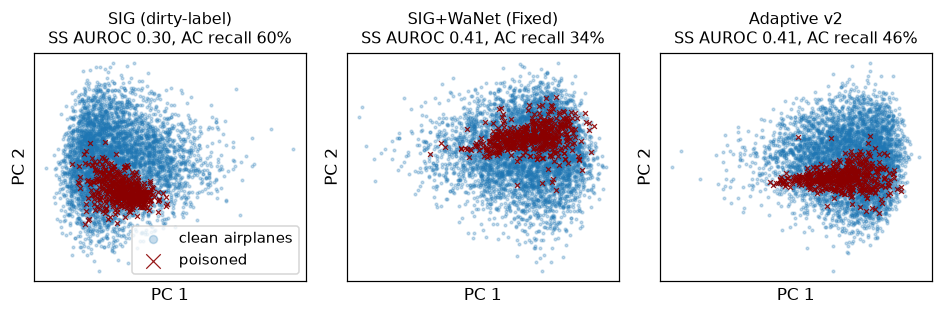

In [7]:
fig, axes = plt.subplots(1, len(feats_for_plot), figsize=(2.9 * len(feats_for_plot), 3.0))
for ax, (name, (f, is_poison)) in zip(axes, feats_for_plot.items()):
    c = f - f.mean(0)
    _, _, vt = np.linalg.svd(c, full_matrices=False)
    z = c @ vt[:2].T
    ax.scatter(*z[~is_poison].T, s=3, alpha=0.25, label="clean airplanes", color="tab:blue")
    ax.scatter(*z[is_poison].T, s=10, alpha=0.9, label="poisoned", color="#8b0000", marker="x", lw=0.8)  # dark, so it shows in greyscale
    r = data_df.set_index("attack").loc[name]
    ax.set_title(f"{name}\nSS AUROC {r.ss_auroc:.2f}, AC recall {r.ac_recall:.0%}", fontsize=10.5)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2")
axes[0].legend(fontsize=9.5, markerscale=3)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/data_level_features.png", bbox_inches="tight"); plt.show()

## 4. Frequency domain

**Energy concentration:** the share of each trigger's change to the image (poisoned - clean, gray) that
sits in its 1 and 10 strongest DCT coefficients, averaged over 1,000 test images.

**DCT detector:** logistic regression on the log-magnitude DCT of the image, trained on 5,000 clean and
5,000 poisoned *training* images and tested on 2,000 clean and 2,000 poisoned *test* images. It is
trained on the same trigger it is tested on, so its AUROC is a best case for the defender.

In [8]:
tr_idx = np.random.RandomState(1).permutation(len(train_base))[:10000]
te = perm[5000:9000]
tr_clean = torch.stack([to_tensor(train_base[i][0]) for i in tr_idx[:5000]])
tr_other = [to_tensor(train_base[i][0]) for i in tr_idx[5000:]]
te_clean = torch.stack([to_tensor(test_base[i][0]) for i in te[:2000]])
te_other = [to_tensor(test_base[i][0]) for i in te[2000:]]
ec_imgs = [to_tensor(test_base[i][0]) for i in perm[:1000]]

rows, spectra, tr_pois, te_pois = [], {}, {}, {}
for name in MODELS:
    attack, _ = load(name)
    clean_ec = torch.stack(ec_imgs)
    pois_ec = torch.stack([attack.poison(x) for x in ec_imgs])
    tr_pois[name] = torch.stack([attack.poison(x) for x in tr_other])
    te_pois[name] = torch.stack([attack.poison(x) for x in te_other])
    r = {"attack": name}
    r.update(energy_concentration(clean_ec, pois_ec))
    r.update(train_dct_detector(tr_clean, tr_pois[name], te_clean, te_pois[name], device=DEVICE))
    rows.append(r)
    spectra[name] = dct2((pois_ec - clean_ec).mean(1)).abs().mean(0).numpy()
    print(f"{name:28s} top-1 energy {r['top1_energy']:.1%}  top-10 {r['top10_energy']:.1%}  "
          f"DCT detector AUROC {r['dct_auroc']:.3f}", flush=True)
freq_df = pd.DataFrame(rows)
freq_df.to_csv(os.path.join(cfg.results_dir, "frequency_results.csv"), index=False)
freq_df.round(3)

Blend                        top-1 energy 37.4%  top-10 62.9%  DCT detector AUROC 0.999


SIG (dirty-label)            top-1 energy 31.0%  top-10 98.5%  DCT detector AUROC 0.999


WaNet                        top-1 energy 3.4%  top-10 19.3%  DCT detector AUROC 0.889


Blend+SIG+WaNet              top-1 energy 19.6%  top-10 58.8%  DCT detector AUROC 0.879


SIG+WaNet (Fixed)            top-1 energy 20.4%  top-10 64.1%  DCT detector AUROC 0.958


SIG+WaNet (Fixed, matched)   top-1 energy 25.6%  top-10 79.7%  DCT detector AUROC 0.961


Adaptive v1                  top-1 energy 20.3%  top-10 63.3%  DCT detector AUROC 0.998


Adaptive v2                  top-1 energy 25.8%  top-10 79.0%  DCT detector AUROC 0.978


,attack,top1_energy,top10_energy,dct_auroc,dct_accuracy
0,Blend,0.374,0.629,0.999,0.988
1,SIG (dirty-label),0.310,0.985,0.999,0.983
2,WaNet,0.034,0.193,0.889,0.812
3,Blend+SIG+WaNet,0.196,0.588,0.879,0.796
4,SIG+WaNet (Fixed),0.204,0.641,0.958,0.887
5,"SIG+WaNet (Fixed, matched)",0.256,0.797,0.961,0.889
6,Adaptive v1,0.203,0.633,0.998,0.981
7,Adaptive v2,0.258,0.790,0.978,0.931


In [9]:
show = ["Blend", "WaNet", "SIG+WaNet (Fixed)", "SIG+WaNet (Fixed, matched)", "Adaptive v2"]
SHORT = {"SIG+WaNet (Fixed)": "Fixed SIG+WaNet", "SIG+WaNet (Fixed, matched)": "Fixed (matched)"}
fig, axes = plt.subplots(1, len(show), figsize=(2.3 * len(show), 2.6))
for ax, name in zip(axes, show):
    im = ax.imshow(np.log10(spectra[name] + 1e-5), cmap="magma", vmin=-4, vmax=0)
    r = freq_df.set_index("attack").loc[name]
    ax.set_title(f"{SHORT.get(name, name)}\ntop-10 energy {r.top10_energy:.0%}", fontsize=9.5)
    ax.set_xticks([]); ax.set_yticks([])
axes[0].set_ylabel("vertical freq. →", fontsize=9.5); axes[0].set_xlabel("horizontal freq. →", fontsize=9.5)
fig.colorbar(im, ax=axes, fraction=0.02, label="log10 mean |DCT| of perturbation")
plt.savefig(f"{FIG_DIR}/trigger_dct_spectra.png", bbox_inches="tight"); plt.show()

C:\Users\ABC\AppData\Local\Temp\ipykernel_13048\1934047953.py:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.savefig(f"{FIG_DIR}/trigger_dct_spectra.png", bbox_inches="tight"); plt.show()


### 4b. Triggers the detector has never seen

A real defender doesn't have examples of a new trigger, so two more realistic setups, with the same
clean images as above:

* **Known single attacks:** train on the three published single attacks (Blend, SIG, WaNet) mixed
  together into one poisoned set of 5,000 images, and test on every trigger.
* **Leave-one-out:** for each trigger, train on the other seven and test on the one left out.

Only the poisoned training images change; everything else is the same as above.

In [10]:
def pooled(names, n=5000):
    """n poisoned training images, the same number from each attack, each clean image used only once."""
    parts = np.array_split(np.arange(n), len(names))
    return torch.cat([tr_pois[nm][idx] for nm, idx in zip(names, parts)])

KNOWN = ["Blend", "SIG (dirty-label)", "WaNet"]
names = list(MODELS)
rows = []
for name in names:
    known = train_dct_detector(tr_clean, pooled(KNOWN), te_clean, te_pois[name], device=DEVICE)
    loo = train_dct_detector(tr_clean, pooled([n for n in names if n != name]), te_clean, te_pois[name], device=DEVICE)
    rows.append({"attack": name, "trained_on_it": freq_df.set_index("attack").loc[name, "dct_auroc"],
                 "known_singles": known["dct_auroc"], "leave_one_out": loo["dct_auroc"],
                 "known_singles_seen": name in KNOWN})
    print(f"{name:28s} seen {rows[-1]['trained_on_it']:.3f}  singles-only {known['dct_auroc']:.3f}  "
          f"leave-one-out {loo['dct_auroc']:.3f}", flush=True)
unseen_df = pd.DataFrame(rows)
unseen_df.to_csv(os.path.join(cfg.results_dir, "frequency_unseen_results.csv"), index=False)
unseen_df.round(3)

Blend                        seen 0.999  singles-only 0.938  leave-one-out 0.601


SIG (dirty-label)            seen 0.999  singles-only 0.886  leave-one-out 0.925


WaNet                        seen 0.889  singles-only 0.738  leave-one-out 0.614


Blend+SIG+WaNet              seen 0.879  singles-only 0.842  leave-one-out 0.865


SIG+WaNet (Fixed)            seen 0.958  singles-only 0.865  leave-one-out 0.905


SIG+WaNet (Fixed, matched)   seen 0.961  singles-only 0.847  leave-one-out 0.890


Adaptive v1                  seen 0.998  singles-only 0.936  leave-one-out 0.969


Adaptive v2                  seen 0.978  singles-only 0.852  leave-one-out 0.900


,attack,trained_on_it,known_singles,leave_one_out,known_singles_seen
0,Blend,0.999,0.938,0.601,True
1,SIG (dirty-label),0.999,0.886,0.925,True
2,WaNet,0.889,0.738,0.614,True
3,Blend+SIG+WaNet,0.879,0.842,0.865,False
4,SIG+WaNet (Fixed),0.958,0.865,0.905,False
5,"SIG+WaNet (Fixed, matched)",0.961,0.847,0.890,False
6,Adaptive v1,0.998,0.936,0.969,False
7,Adaptive v2,0.978,0.852,0.900,False


## 5. Neural Cleanse

For each model and each of the 10 classes, a mask and pattern are optimised on 2,000 clean test images
(the defender's data) so that stamped images get classified as that class, with an adaptive L1 penalty
on the mask (30 epochs). The backdoor's target class should need a much smaller mask than the others.
**Anomaly index** = (median L1 - L1 of the class) / (1.4826 × MAD), and a class is flagged above 2.

Models: all eight 1% models, the clean model (no backdoor, so nothing should be flagged), the BadNets
sanity check, and the four SIG+WaNet variants at 0.5% and 5% as well.

In [11]:
N_DEF = 5000
def_x = torch.stack([to_tensor(test_base[i][0]) for i in perm[:N_DEF]])
def_y = torch.tensor([test_base[i][1] for i in perm[:N_DEF]])
ev_x = torch.stack([to_tensor(test_base[i][0]) for i in perm[N_DEF:]])
ev_y = torch.tensor([test_base[i][1] for i in perm[N_DEF:]])

SWEEP = ["SIG+WaNet (Fixed)", "SIG+WaNet (Fixed, matched)", "Adaptive v1", "Adaptive v2"]
RUNS = ([(n, RATE) for n in ["Clean model", "BadNets (control)"] + list(MODELS)]
        + [(n, r) for r in (0.005, 0.05) for n in SWEEP])
nc_rows, nc_detail = [], {}
for name, rate in RUNS:
    _, model = load(name, rate)
    r = neural_cleanse(model, def_x[:2000], NORMALIZE, num_classes=cfg.num_classes,
                       target_label=cfg.target_label, device=DEVICE)
    nc_detail[name, rate] = r
    nc_rows.append({"model": name, "poison_rate": 0.0 if name == "Clean model" else rate,
                    **{k: v for k, v in r.items() if k not in ("nc_l1_all", "nc_masks", "nc_patterns")}})
    print(f"{name:28s} {rate:.3f}  target L1 {r['nc_target_l1']:6.1f}  median {r['nc_median_l1']:6.1f}  "
          f"target anomaly {r['nc_target_anomaly']:5.2f}  max anomaly {r['nc_max_anomaly']:5.2f}  "
          f"flagged [{r['nc_flagged']}]", flush=True)
nc_df = pd.DataFrame(nc_rows)
nc_df.to_csv(os.path.join(cfg.results_dir, "neural_cleanse_results.csv"), index=False)
# mask size of every class, for the threshold sweep in section 6b
pd.DataFrame([{"model": n, "poison_rate": 0.0 if n == "Clean model" else r,
               **{f"l1_class{t}": v for t, v in enumerate(d["nc_l1_all"])}}
              for (n, r), d in nc_detail.items()]).to_csv(
    os.path.join(cfg.results_dir, "neural_cleanse_l1_all.csv"), index=False)
nc_df.round(2)

Clean model                  0.010  target L1   33.9  median   31.2  target anomaly -0.73  max anomaly  1.69  flagged []


BadNets (control)            0.010  target L1    3.6  median   22.2  target anomaly  4.32  max anomaly  4.32  flagged [0]


Blend                        0.010  target L1    7.8  median   29.4  target anomaly  8.29  max anomaly  8.29  flagged [0]


SIG (dirty-label)            0.010  target L1   29.4  median   31.7  target anomaly  0.70  max anomaly  1.25  flagged []


WaNet                        0.010  target L1   18.5  median   28.3  target anomaly  1.76  max anomaly  1.76  flagged []


...

SIG+WaNet (Fixed)            0.050  target L1   26.5  median   28.7  target anomaly  0.77  max anomaly  1.27  flagged []


SIG+WaNet (Fixed, matched)   0.050  target L1   26.5  median   34.1  target anomaly  3.11  max anomaly  3.11  flagged [0,1]


Adaptive v1                  0.050  target L1   41.3  median   28.9  target anomaly -2.66  max anomaly  0.93  flagged []


Adaptive v2                  0.050  target L1   32.4  median   30.6  target anomaly -0.91  max anomaly  2.94  flagged [1,2]


,model,poison_rate,nc_target_l1,nc_median_l1,nc_min_other_l1,nc_target_anomaly,nc_max_anomaly,nc_flagged,nc_detected
0,Clean model,0.00,33.95,31.17,24.78,-0.73,1.69,,False
1,BadNets (control),0.01,3.61,22.24,14.01,4.32,4.32,0,True
2,Blend,0.01,7.79,29.41,25.47,8.29,8.29,0,True
3,SIG (dirty-label),0.01,29.44,31.73,27.62,0.70,1.25,,False
4,WaNet,0.01,18.55,28.30,21.15,1.76,1.76,,False
5,Blend+SIG+WaNet,0.01,26.24,29.29,25.02,1.32,1.84,,False
6,SIG+WaNet (Fixed),0.01,33.45,32.44,24.15,-0.22,1.83,,False
7,"SIG+WaNet (Fixed, matched)",0.01,32.05,32.85,25.45,0.21,1.91,,False
8,Adaptive v1,0.01,29.22,32.96,30.06,1.02,1.02,,False
9,Adaptive v2,0.01,23.90,29.19,27.02,1.62,1.62,,False


In [12]:
show = ["BadNets (control)", "Clean model", "SIG+WaNet (Fixed)", "Adaptive v2"]
fig, axes = plt.subplots(2, len(show), figsize=(2.6 * len(show), 5.0),
                         gridspec_kw={"height_ratios": [1.2, 1]})
for c, name in enumerate(show):
    r = nc_detail[name, RATE]
    ax = axes[0, c]
    cols = ["tab:red" if t == cfg.target_label else "tab:gray" for t in range(cfg.num_classes)]
    ax.bar(range(cfg.num_classes), r["nc_l1_all"], color=cols)
    ax.set_title(f"{name}\nanomaly index {r['nc_target_anomaly']:.2f}", fontsize=9.5)
    ax.set_xticks(range(cfg.num_classes)); ax.set_xticklabels(range(cfg.num_classes), fontsize=8)
    ax.set_xlabel("class")
    if c == 0: ax.set_ylabel("mask L1 norm")
    m, pt = r["nc_masks"][cfg.target_label][0], r["nc_patterns"][cfg.target_label][0]
    axes[1, c].imshow((m * pt).permute(1, 2, 0).clamp(0, 1).numpy(), interpolation="nearest")
    axes[1, c].set_xticks([]); axes[1, c].set_yticks([])
    axes[1, c].set_xlabel("reversed trigger (airplane)", fontsize=9)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/neural_cleanse.png", bbox_inches="tight"); plt.show()

C:\Users\ABC\AppData\Local\Temp\ipykernel_13048\3466516253.py:17: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.savefig(f"{FIG_DIR}/neural_cleanse.png", bbox_inches="tight"); plt.show()


## 6. Fine-Pruning

The 512 channels of ResNet-18's last stage (`layer4`) are ranked by how active they are on the
defender's 5,000 clean test images, and the least active ones are pruned 5% at a time, as long as the
defender's clean accuracy drops by no more than 5 points. The pruned model is then fine-tuned for 5
epochs on the same 5,000 images (SGD, lr 0.01). CA and ASR are measured on the other 5,000 test images
(ASR on the non-airplane ones).

In [13]:
fp_rows = []
for name, rate in RUNS:
    if name == "Clean model":
        continue
    attack, model = load(name, rate)
    ev_p = torch.stack([attack.poison(x) for x in ev_x[ev_y != cfg.target_label]])
    r = fine_prune(model, "layer4", def_x, def_y, ev_x, ev_y, ev_p, cfg.target_label, NORMALIZE, device=DEVICE)
    fp_rows.append({"model": name, "poison_rate": rate, **r})
    print(f"{name:28s} {rate:.3f}  pruned {r['fp_pruned_fraction']:.0%}  ASR {r['asr_before']:.1%} -> "
          f"{r['asr_pruned']:.1%} (pruned) -> {r['asr_finetuned']:.1%} (fine-tuned)  CA {r['ca_before']:.1%} -> "
          f"{r['ca_finetuned']:.1%}", flush=True)
fp_df = pd.DataFrame(fp_rows)
fp_df.to_csv(os.path.join(cfg.results_dir, "fine_pruning_results.csv"), index=False)
fp_df.round(4)

BadNets (control)            0.010  pruned 85%  ASR 100.0% -> 99.9% (pruned) -> 100.0% (fine-tuned)  CA 87.7% -> 87.7%


Blend                        0.010  pruned 90%  ASR 96.4% -> 94.9% (pruned) -> 91.0% (fine-tuned)  CA 87.5% -> 86.9%


SIG (dirty-label)            0.010  pruned 90%  ASR 99.1% -> 99.1% (pruned) -> 95.0% (fine-tuned)  CA 87.4% -> 87.2%


WaNet                        0.010  pruned 90%  ASR 54.3% -> 67.8% (pruned) -> 29.2% (fine-tuned)  CA 88.1% -> 87.6%


Blend+SIG+WaNet              0.010  pruned 90%  ASR 89.6% -> 88.2% (pruned) -> 70.2% (fine-tuned)  CA 88.3% -> 87.7%


...

SIG+WaNet (Fixed)            0.050  pruned 85%  ASR 99.0% -> 98.8% (pruned) -> 86.6% (fine-tuned)  CA 87.9% -> 87.9%


SIG+WaNet (Fixed, matched)   0.050  pruned 85%  ASR 99.3% -> 97.4% (pruned) -> 69.1% (fine-tuned)  CA 87.4% -> 86.7%


Adaptive v1                  0.050  pruned 90%  ASR 100.0% -> 99.9% (pruned) -> 79.3% (fine-tuned)  CA 87.4% -> 87.0%


Adaptive v2                  0.050  pruned 85%  ASR 99.6% -> 99.4% (pruned) -> 76.2% (fine-tuned)  CA 88.4% -> 87.8%


,model,poison_rate,fp_pruned_fraction,ca_before,asr_before,ca_pruned,asr_pruned,ca_finetuned,asr_finetuned
0,BadNets (control),0.010,0.8496,0.8772,1.0000,0.8402,0.9989,0.8768,1.0000
1,Blend,0.010,0.8984,0.8746,0.9643,0.8160,0.9486,0.8688,0.9105
2,SIG (dirty-label),0.010,0.8984,0.8740,0.9906,0.8274,0.9906,0.8720,0.9502
3,WaNet,0.010,0.8984,0.8810,0.5428,0.8426,0.6783,0.8758,0.2923
4,Blend+SIG+WaNet,0.010,0.8984,0.8828,0.8964,0.8406,0.8817,0.8768,0.7022
5,SIG+WaNet (Fixed),0.010,0.8984,0.8806,0.9556,0.8288,0.9384,0.8742,0.7426
6,"SIG+WaNet (Fixed, matched)",0.010,0.8496,0.8770,0.9632,0.8478,0.9853,0.8750,0.8475
7,Adaptive v1,0.010,0.8984,0.8816,0.9946,0.8456,0.9958,0.8830,0.9732
8,Adaptive v2,0.010,0.8984,0.8750,0.9743,0.8338,0.9855,0.8750,0.8839
9,SIG+WaNet (Fixed),0.005,0.7500,0.8790,0.8716,0.8366,0.9245,0.8724,0.7207


### 6b. How much do the results depend on the defence settings?

Both defences have a setting that I picked from the papers: the anomaly-index threshold for Neural
Cleanse (2) and the clean-accuracy budget for Fine-Pruning (5 points). To check that the conclusions
don't hinge on those choices:

* **Neural Cleanse threshold:** using the mask sizes already computed above, count how many models get
  their real target class flagged, and how many get a wrong (clean) class flagged, at thresholds 1.5,
  2, 2.5 and 3.
* **Fine-Pruning budget:** run Fine-Pruning again on the 1% models with budgets of 2 and 10 points
  (5 points is above), so it prunes less or more.

In [14]:
from defenses.neural_cleanse import anomaly_indices
l1 = pd.read_csv(os.path.join(cfg.results_dir, "neural_cleanse_l1_all.csv"))
classes = [c for c in l1.columns if c.startswith("l1_class")]
rows = []
for thr in (1.5, 2.0, 2.5, 3.0):
    flags = []
    for _, r in l1.iterrows():
        ai = -anomaly_indices(r[classes].to_numpy(dtype=float))        # positive = smaller than the median
        flagged = {t for t in range(len(classes)) if ai[t] > thr}
        flags.append((r.model, r.poison_rate, cfg.target_label in flagged, bool(flagged - {cfg.target_label})))
    f = pd.DataFrame(flags, columns=["model", "poison_rate", "target_flagged", "other_flagged"])
    project = f[~f.model.isin(["Clean model", "BadNets (control)", "Blend"])]
    rows.append({"threshold": thr,
                 "badnets_detected": bool(f[f.model == "BadNets (control)"].target_flagged.iloc[0]),
                 "blend_detected": bool(f[f.model == "Blend"].target_flagged.iloc[0]),
                 "clean_model_false_alarm": bool(f[f.model == "Clean model"].other_flagged.iloc[0]),
                 "sig_wanet_models_detected": int(project.target_flagged.sum()),
                 "sig_wanet_models_total": len(project),
                 "models_with_false_alarm": int(f.other_flagged.sum()),
                 "models_total": len(f)})
nc_sens = pd.DataFrame(rows)
nc_sens.to_csv(os.path.join(cfg.results_dir, "neural_cleanse_threshold_sensitivity.csv"), index=False)
nc_sens

,threshold,badnets_detected,blend_detected,clean_model_false_alarm,sig_wanet_models_detected,sig_wanet_models_total,models_with_false_alarm,models_total
0,1.5,True,True,True,3,15,10,18
1,2.0,True,True,False,1,15,3,18
2,2.5,True,True,False,1,15,2,18
3,3.0,True,True,False,1,15,0,18


In [15]:
fp_rows2 = [{"max_ca_drop": 0.05, **r} for r in fp_rows if r["poison_rate"] == RATE]
for budget in (0.02, 0.10):
    for name in ["BadNets (control)"] + list(MODELS):
        attack, model = load(name, RATE)
        ev_p = torch.stack([attack.poison(x) for x in ev_x[ev_y != cfg.target_label]])
        r = fine_prune(model, "layer4", def_x, def_y, ev_x, ev_y, ev_p, cfg.target_label, NORMALIZE,
                       device=DEVICE, max_ca_drop=budget)
        fp_rows2.append({"max_ca_drop": budget, "model": name, "poison_rate": RATE, **r})
        print(f"budget {budget:.2f}  {name:28s} pruned {r['fp_pruned_fraction']:.0%}  ASR {r['asr_before']:.1%} -> "
              f"{r['asr_finetuned']:.1%}  CA {r['ca_before']:.1%} -> {r['ca_finetuned']:.1%}", flush=True)
fp_sens = pd.DataFrame(fp_rows2)
fp_sens.to_csv(os.path.join(cfg.results_dir, "fine_pruning_budget_sensitivity.csv"), index=False)
fp_sens.pivot_table(index="model", columns="max_ca_drop", values="asr_finetuned", sort=False).mul(100).round(1)

budget 0.02  BadNets (control)            pruned 80%  ASR 100.0% -> 100.0%  CA 87.7% -> 87.5%


budget 0.02  Blend                        pruned 80%  ASR 96.4% -> 89.3%  CA 87.5% -> 86.7%


budget 0.02  SIG (dirty-label)            pruned 80%  ASR 99.1% -> 96.0%  CA 87.4% -> 87.1%


budget 0.02  WaNet                        pruned 75%  ASR 54.3% -> 32.6%  CA 88.1% -> 87.6%


budget 0.02  Blend+SIG+WaNet              pruned 80%  ASR 89.6% -> 73.2%  CA 88.3% -> 87.4%


...

budget 0.10  SIG+WaNet (Fixed)            pruned 95%  ASR 95.6% -> 71.8%  CA 88.1% -> 87.4%


budget 0.10  SIG+WaNet (Fixed, matched)   pruned 90%  ASR 96.3% -> 83.3%  CA 87.7% -> 87.6%


budget 0.10  Adaptive v1                  pruned 90%  ASR 99.5% -> 97.3%  CA 88.2% -> 88.3%


budget 0.10  Adaptive v2                  pruned 95%  ASR 97.4% -> 86.8%  CA 87.5% -> 87.4%


max_ca_drop,0.05,0.02,0.10
model,,,
BadNets (control),100.0,100.0,100.0
Blend,91.0,89.3,91.0
SIG (dirty-label),95.0,96.0,92.8
WaNet,29.2,32.6,29.0
Blend+SIG+WaNet,70.2,73.2,70.2
SIG+WaNet (Fixed),74.3,80.0,71.8
"SIG+WaNet (Fixed, matched)",84.8,88.7,83.3
Adaptive v1,97.3,98.2,97.3
Adaptive v2,88.4,90.0,86.8
